# Notebook 4: Testing Modified SGP4 on Etalon-1 and Etalon-2


Note that the positional and velocity outputs below are in the True Equator Mean Equinox (TEME) reference frame according to [SGP4 PyPI documentation](https://pypi.org/project/sgp4/), and these are handled internally by Brent for TEME-GCRF conversion.

In [1]:
# Imports and paths
import os
import sys
import subprocess
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

# Prevent path errors:
os.environ["JAVA_HOME"] = str(Path(sys.prefix) / "Library" / "jre")

from brent import Constants
from brent.propagators.analytical.tle import (
    TLEPropagator,
    TLEPropagatorMethod,
)

# Paths:
repo_path = Path.cwd().resolve()
if repo_path.name == "experiments":
    repo_path = repo_path.parent

data_path = repo_path / "data"  # data folder
download_path = repo_path / "download"  # downloads folder for TLEs/SP3

# Output paths:
comparison_path = data_path / "sgp4mods-comparison"  # writing data files
comparison_path.mkdir(parents=True, exist_ok=True)

## Obtaining Satellite States for Modified SGP4 Implementation (Hujsak $C_X$):

In [2]:
satellites = {
    "Etalon 1": {
        "folder": "etalon1",
        "norad": "19751",
    },
    "Etalon 2": {
        "folder": "etalon2",
        "norad": "20026",
    },
}

In [3]:
state_columns = [
    "x_m", "y_m", "z_m",
    "vx_m_s", "vy_m_s", "vz_m_s",
]

for name, info in satellites.items():
    folder = info["folder"]

    # Existing inputs:
    tle_path = download_path / "tle" / f'{info["norad"]}.json'
    sp3_path = data_path / "states" / f"{folder}_sp3_2025.csv"

    # New modified-SGP4 output:
    output_file = (
        comparison_path / f"{folder}_hujsak_full_cx_2025.csv"
    )

    # Protect previously saved results:
    if output_file.exists():
        raise FileExistsError(f"File already exists: {output_file}")

    # Use this satellite's existing SP3 epochs:
    sp3_df = pd.read_csv(sp3_path, parse_dates=["epoch_utc"])
    dates = sp3_df["epoch_utc"]

    print(f"\n{name}")
    print(f"Number of epochs: {len(dates)}")
    print(f"First epoch: {dates.iloc[0]}")
    print(f"Last epoch: {dates.iloc[-1]}")
    print(f"Output: {output_file.name}")

    # Load TLEs with the currently installed modified implementation:
    tle = TLEPropagator.load(
        path=str(tle_path),
        method=TLEPropagatorMethod.FORWARD,
    )

    # Propagate at the SP3 epochs:
    states = []

    for timestamp in dates:
        state = np.asarray(
            tle._propagate(
                timestamp.to_pydatetime(),
                Constants.DEFAULT_ECI,
            ),
            dtype=float,
        )
        states.append(state)

    # GCRF positions in metres and velocities in metres per second:
    states_df = pd.DataFrame(states, columns=state_columns)
    states_df.insert(0, "epoch_utc", dates.to_numpy())

    # Save without overwriting:
    states_df.to_csv(output_file, index=False, mode="x")

    print(f"Saved {len(states_df)} states to: {output_file}")


Etalon 1
Number of epochs: 8471
First epoch: 2025-01-01 00:00:00
Last epoch: 2025-12-27 23:00:00
Output: etalon1_hujsak_full_cx_2025.csv
Saved 8471 states to: C:\Users\lette\OneDrive\Desktop\Imperial PhD\Year 1\brent\data\sgp4mods-comparison\etalon1_hujsak_full_cx_2025.csv

Etalon 2
Number of epochs: 8494
First epoch: 2025-01-01 00:00:00
Last epoch: 2025-12-27 23:00:00
Output: etalon2_hujsak_full_cx_2025.csv
Saved 8494 states to: C:\Users\lette\OneDrive\Desktop\Imperial PhD\Year 1\brent\data\sgp4mods-comparison\etalon2_hujsak_full_cx_2025.csv


Comparing the nominal $C_X$ Hujsak with the baseline SGP4 implementation.

In [10]:
# Running script from Jupyter notebook + bypassing kernel crash:
conda_path = Path(sys.prefix)

# Include Conda's DLL directories
env = os.environ.copy()
env["PATH"] = os.pathsep.join([
    str(conda_path),
    str(conda_path / "Library" / "bin"),
    str(conda_path / "Library" / "usr" / "bin"),
    str(conda_path / "Scripts"),
    env.get("PATH", "")
])

# Run plotting script in a separate process
subprocess.run([sys.executable, "plot_nominal_sgp4mod.py"], env=env, check=True)

CompletedProcess(args=['c:\\Users\\lette\\anaconda3\\envs\\brent\\python.exe', 'plot_nominal_sgp4mod.py'], returncode=0)

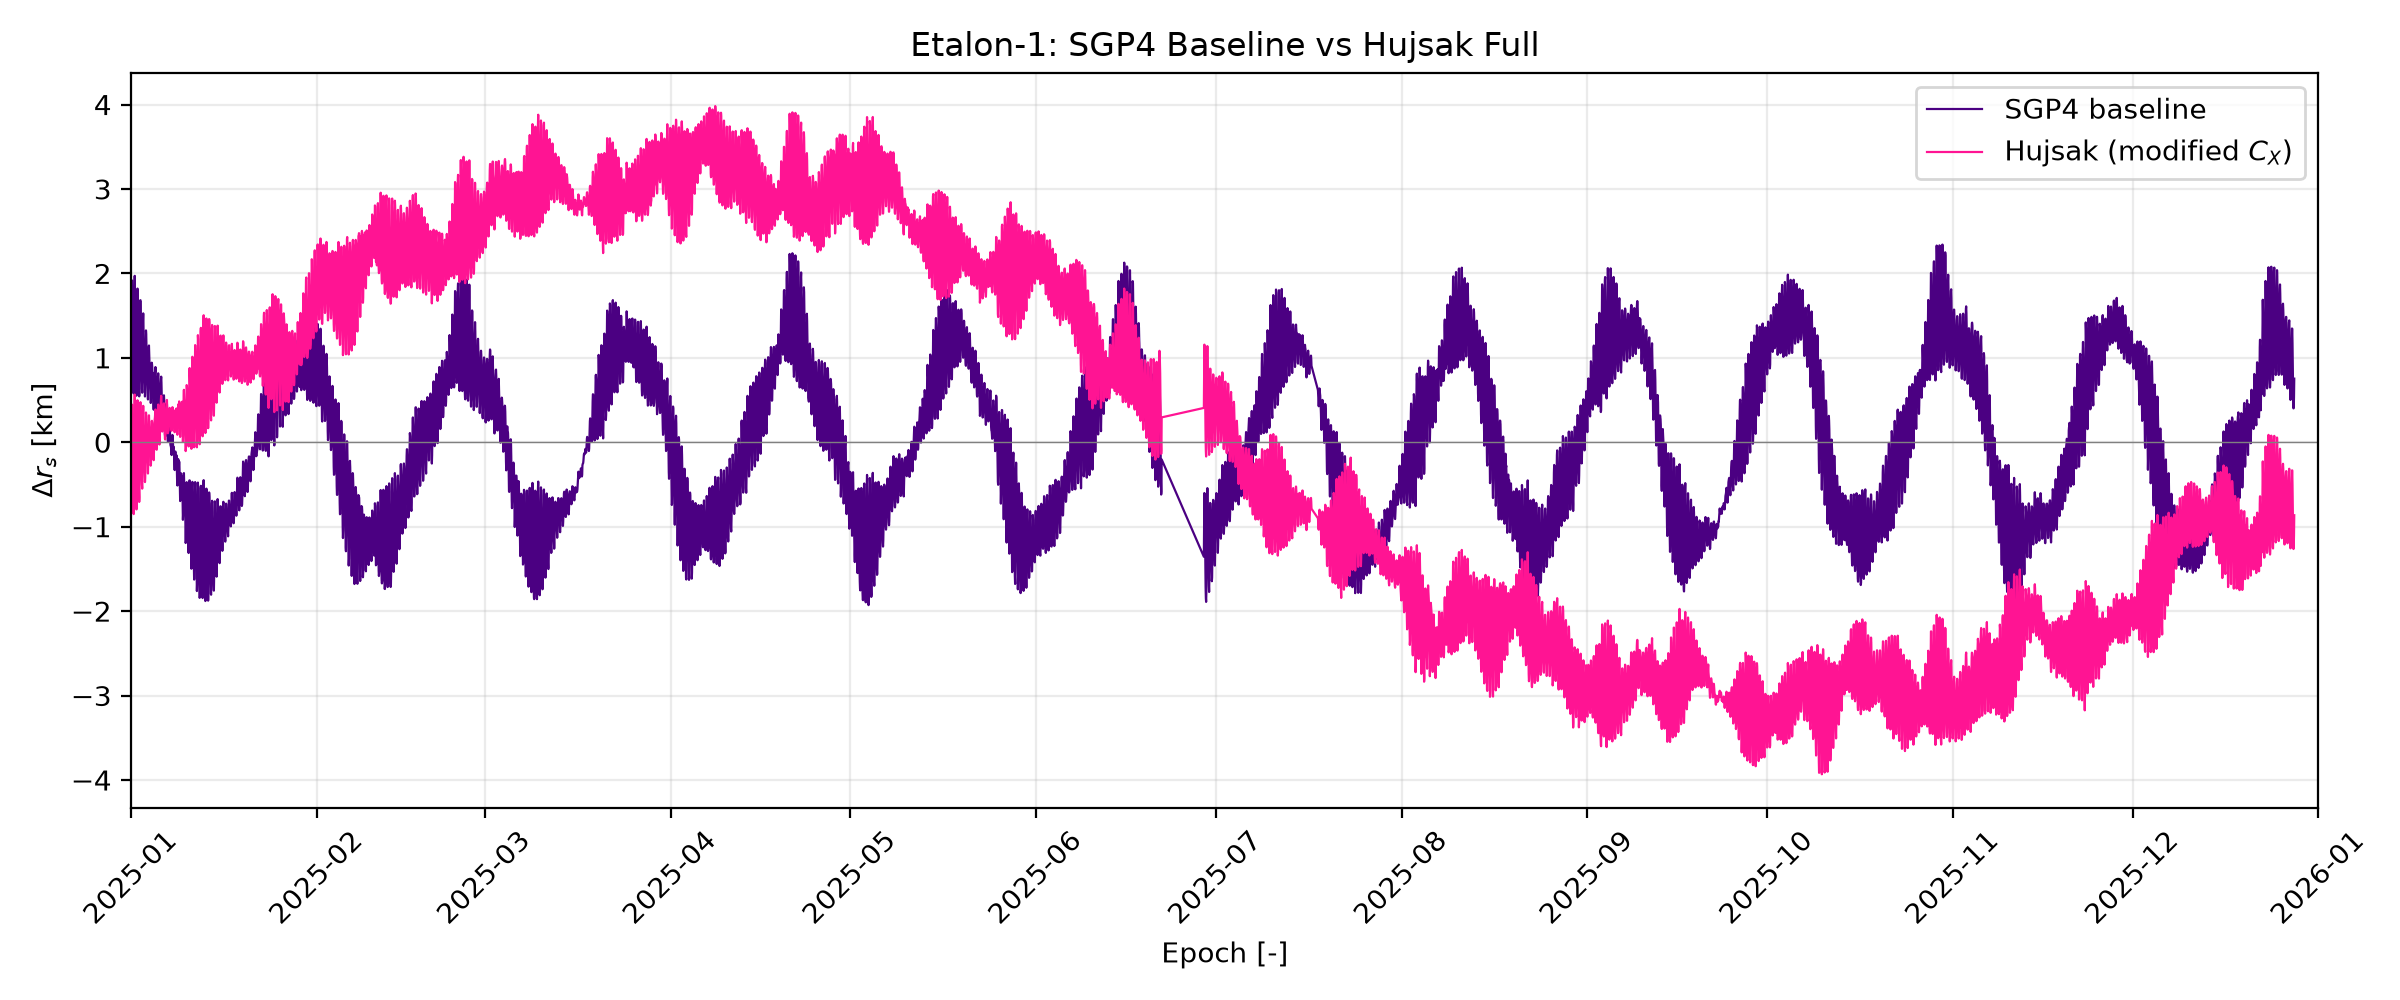

In [11]:
(Image(filename="figures/etalon1_baseline_vs_hujsak_2025.png", width=800))